In [1]:
import sys, os, distutils.core
sys.path.insert(0, os.path.abspath('./detectron2'))
sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath('./projects/Panoptic-DeepLab/'))
os.environ['DETECTRON2_DATASETS'] = '/home/liwa/data/datasets/'

In [12]:
from detectron2.data import DatasetCatalog
from detectron2.config import get_cfg
from pathlib import Path
import random

from detectron2.config import get_cfg
from detectron2.projects.panoptic_deeplab import (
    PanopticDeeplabDatasetMapper,
    add_panoptic_deeplab_config,
)

In [13]:
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "max_split_size_mb:8700m"
cfg = get_cfg()
add_panoptic_deeplab_config(cfg)
# add project-specific config (e.g., TensorMask) here if you're not running a model in detectron2's core library
cfg.merge_from_file("/home/liwa/data/PytrochDeepyeast/projects/Panoptic-DeepLab/configs/yeast_panoptics/config.yaml")

cfg.MODEL.DEVICE = "cuda"
# into cpu model
# cfg.MODEL.SEM_SEG_HEAD.NORM = "BN"
# cfg.MODEL.INS_EMBED_HEAD.NORM = "BN"
# cfg.MODEL.RESNETS.NORM = "BN"

cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.3 # set threshold for this model

# Find a model from detectron2's model zoo. You can use the https://dl.fbaipublicfiles... url as well
cfg.MODEL.WEIGHTS = os.path.abspath("/home/liwa/data/oneformer_output/output/model_0119999_v3.pth")

In [14]:
cfg.DATASETS

CfgNode({'TRAIN': ('yeastcity_train',), 'PROPOSAL_FILES_TRAIN': (), 'PRECOMPUTED_PROPOSAL_TOPK_TRAIN': 2000, 'TEST': ('yeastcity_val',), 'PROPOSAL_FILES_TEST': (), 'PRECOMPUTED_PROPOSAL_TOPK_TEST': 1000})

In [21]:
dataset_dicts = DatasetCatalog.get(cfg.DATASETS.TRAIN[0])

print(f"Dataset: {cfg.DATASETS.TRAIN[0]}")
print(f"Number of images: {len(dataset_dicts)}")
print("Example record:")
# print(dataset_dicts[0])

required_keys = {
    "file_name",
    "image_id",
    "pan_seg_file_name",
    "sem_seg_file_name",
    "segments_info",
}

for i, record in enumerate(dataset_dicts):
    missing = required_keys - record.keys()
    if missing:
        raise ValueError(f"Record {i} is missing keys: {missing}")

    if not Path(record["file_name"]).is_file():
        raise FileNotFoundError(
            f"Image does not exist: {record['file_name']}"
        )

    if not Path(record["pan_seg_file_name"]).is_file():
        raise FileNotFoundError(
            f"Panoptic mask does not exist: "
            f"{record['pan_seg_file_name']}"
        )

    segment_ids = [x["id"] for x in record["segments_info"]]

    if len(segment_ids) != len(set(segment_ids)):
        raise ValueError(
            f"Duplicate segment IDs in {record['file_name']}"
        )

print("Raw dataset records passed basic checks.")

Dataset: yeastcity_train
Number of images: 1000
Example record:
Raw dataset records passed basic checks.


In [29]:
from train_net_yeast import Trainer
import torch

In [34]:
loader = Trainer.build_train_loader(cfg)
batch = next(iter(loader))

print(f"Batch size: {len(batch)}")

for i, sample in enumerate(batch[:2]):
    print(f"\nSample {i}")
    print("file_name:", sample.get("file_name"))
    print("keys:", sample.keys())

    for key, value in sample.items():
        if torch.is_tensor(value):
            print(
                f"{key:20s}",
                f"shape={tuple(value.shape)}",
                f"dtype={value.dtype}",
                f"min={value.min().item():.3f}",
                f"max={value.max().item():.3f}",
                f"finite={torch.isfinite(value).all().item()}",
            )

Batch size: 32

Sample 0
file_name: /home/liwa/data/datasets/yeastcity/leftImg8bit/train/0801_0900/00844_leftImg8bit.png
keys: dict_keys(['file_name', 'image_id', 'sem_seg_file_name', 'width', 'height', 'segments_info', 'image', 'sem_seg', 'center', 'center_points', 'offset', 'sem_seg_weights', 'center_weights', 'offset_weights'])
image                shape=(3, 512, 512) dtype=torch.uint8 min=1.000 max=128.000 finite=True
sem_seg              shape=(512, 512) dtype=torch.int64 min=0.000 max=0.000 finite=True
center               shape=(512, 512) dtype=torch.float32 min=0.000 max=0.000 finite=True
offset               shape=(2, 512, 512) dtype=torch.float32 min=0.000 max=0.000 finite=True
sem_seg_weights      shape=(512, 512) dtype=torch.float32 min=1.000 max=1.000 finite=True
center_weights       shape=(1, 512, 512) dtype=torch.float32 min=1.000 max=1.000 finite=True
offset_weights       shape=(1, 512, 512) dtype=torch.float32 min=0.000 max=0.000 finite=True

Sample 1
file_name: /home/

In [49]:
loader_iter = iter(loader)

for batch_index in range(1):
    batch = next(loader_iter)

    for sample in batch:
        print(
            batch_index,
            Path(sample["file_name"]).name,
            torch.unique(sample["sem_seg"]).tolist(),
        )

0 00844_leftImg8bit.png [0, 1]
0 00013_leftImg8bit.png [0, 1, 3, 4]
0 00762_leftImg8bit.png [0, 1, 2, 3]
0 00787_leftImg8bit.png [0, 1]
0 00272_leftImg8bit.png [0, 1]
0 00986_leftImg8bit.png [0, 1]
0 00998_leftImg8bit.png [0]
0 00152_leftImg8bit.png [0, 1, 4, 6]
0 00481_leftImg8bit.png [0, 1, 4, 5, 6, 7]
0 00055_leftImg8bit.png [0, 1, 2, 3, 4, 7]
0 00545_leftImg8bit.png [0, 1, 2, 3, 4, 5]
0 00420_leftImg8bit.png [0, 2, 4, 5, 6]
0 00028_leftImg8bit.png [0, 1, 3, 4]
0 00159_leftImg8bit.png [0, 1]
0 00742_leftImg8bit.png [0]
0 00817_leftImg8bit.png [0, 1, 2, 3]
0 00963_leftImg8bit.png [0, 1, 2]
0 00599_leftImg8bit.png [0, 1, 2, 4, 6]
0 00893_leftImg8bit.png [0, 1]
0 00335_leftImg8bit.png [0, 1, 3, 4]
0 00268_leftImg8bit.png [0, 1]
0 00162_leftImg8bit.png [0, 1]
0 00674_leftImg8bit.png [0, 1, 2, 3]
0 00891_leftImg8bit.png [0, 1, 2, 5]
0 00005_leftImg8bit.png [0, 1, 2, 3, 4, 7]
0 00065_leftImg8bit.png [0, 1, 3, 4]
0 00711_leftImg8bit.png [0, 1, 2]
0 00516_leftImg8bit.png [0, 1, 3, 4]
0 0011

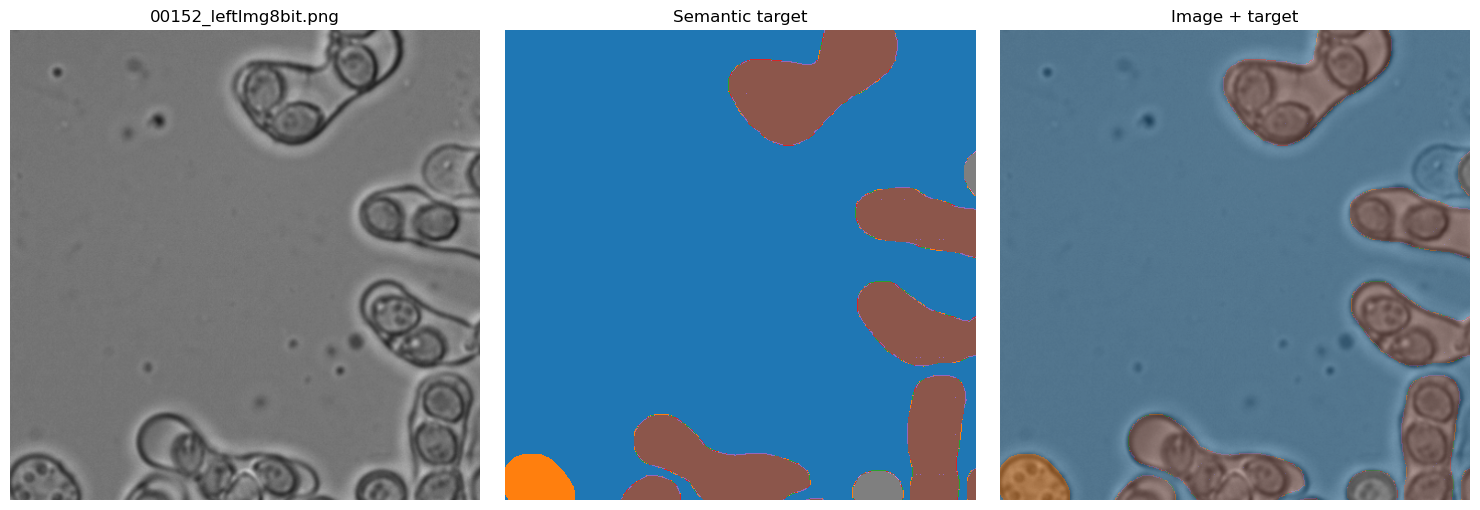

In [53]:
import matplotlib.pyplot as plt
import numpy as np

sample = batch[7]

image = sample["image"].cpu().numpy().transpose(1, 2, 0)
sem_seg = sample["sem_seg"].cpu().numpy()

# Undo Detectron2 normalization for display
# mean = np.asarray(cfg.MODEL.PIXEL_MEAN)
# std = np.asarray(cfg.MODEL.PIXEL_STD)

# image = image * std + mean
# image = np.clip(image, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title(Path(sample["file_name"]).name)

axes[1].imshow(sem_seg, vmin=0, vmax=8, cmap="tab10")
axes[1].set_title("Semantic target")

axes[2].imshow(image)
axes[2].imshow(
    np.ma.masked_where(sem_seg == 255, sem_seg),
    vmin=0,
    vmax=8,
    cmap="tab10",
    alpha=0.4,
)
axes[2].set_title("Image + target")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [54]:
model = Trainer.build_model(cfg)
model.train()

with torch.no_grad():
    losses = model(batch)

print("\nForward-pass losses:")
for name, value in losses.items():
    print(
        f"{name:25s}",
        value.item(),
        "finite:",
        torch.isfinite(value).item(),
    )

RuntimeError: Default process group has not been initialized, please make sure to call init_process_group.